In [ ]:
# -------------------------------------------------
# Single cell: imports + guaranteed fall‑backs
# -------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re                      # regular‑expression utilities
import pathlib                 # path handling
import os                      # needed for makedirs

from itertools import combinations   # for category‑pair counting
from collections import Counter      # for frequency counters

import nltk
nltk.download('stopwords', quiet=True)    # first download attempt
nltk.download('punkt',  quiet=True)      # first download attempt

# ------- fallback stop‑word set (always defined) -------
ENGLISH_STOP_WORDS = {
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves",
    "you", "your", "yours", "yourself", "yourselves", "he", "him",
    "his", "himself", "she", "her", "hers", "herself", "it", "its",
    "itself", "they", "them", "their", "theirs", "themselves"
}

# ------- fallback tokenizer (regex based, never needs NLTK) -------
def simple_tokenize(text: str):
    tokens = re.split(r'\s+', text.strip())
    tokens = [re.sub(r'^\W+|\W+$', '', tok) for tok in tokens]
    tokens = [tok.lower() for tok in tokens if tok]
    return tokens

# Expose them for the whole notebook
globals()['ENGLISH_STOP_WORDS'] = ENGLISH_STOP_WORDS
globals()['simple_tokenize'] = simple_tokenize

# Visualisation style
sns.set_style("whitegrid")
warnings.filterwarnings("ignore")

# Make sure the folder where we save PNGs exists
os.makedirs("/kaggle/working/images", exist_ok=True)
# -------------------------------------------------










**1. Shape of the Dataset**

In [2]:
import pathlib

PARQUET_PATH = pathlib.Path("/kaggle/input/datasets/mohammadibraheem71/arxiv-papers-cleaned/papers.parquet")

# Safety check – the file should be there because you added the dataset in Kaggle UI
if not PARQUET_PATH.exists():
    raise FileNotFoundError(f"Parquet not found at {PARQUET_PATH}")

df = pd.read_parquet(PARQUET_PATH)
print("Shape :", df.shape)
print("Columns:", df.columns.tolist())
df.head()

Shape : (119919, 11)
Columns: ['id', 'title', 'abstract', 'text_raw', 'text_lemma', 'primary_category', 'categories', 'date', 'year', 'month', 'quarter']


,id,title,abstract,text_raw,text_lemma,primary_category,categories,date,year,month,quarter
0,1801.00384,Error-Robust Multi-View Clustering,"In the era of big data, data may come from mul...",Error-Robust Multi-View Clustering. In the era...,error robust multi view clustering era big dat...,cs.LG,cs.LG,2018-01-01 02:42:04,2018,1,2018Q1
1,1801.00388,Beyond Word Embeddings: Learning Entity and Co...,Text representations using neural word embeddi...,Beyond Word Embeddings: Learning Entity and Co...,word embedding learning entity concept represe...,cs.CL,cs.CL cs.AI cs.IR cs.SI,2018-01-01 03:43:30,2018,1,2018Q1
2,1801.00409,PronouncUR: An Urdu Pronunciation Lexicon Gene...,State-of-the-art speech recognition systems re...,PronouncUR: An Urdu Pronunciation Lexicon Gene...,pronouncur urdu pronunciation lexicon generato...,cs.CL,cs.CL,2018-01-01 07:54:09,2018,1,2018Q1
3,1801.00453,Automated rating of recorded classroom present...,Effective presentation skills can help to succ...,Automated rating of recorded classroom present...,automated rating record classroom presentation...,cs.CL,cs.CL cs.AI,2018-01-01 14:56:56,2018,1,2018Q1
4,1801.00470,Script Identification in Natural Scene Image a...,Script identification plays a significant role...,Script Identification in Natural Scene Image a...,script identification natural scene image vide...,cs.CV,cs.CV,2018-01-01 16:42:50,2018,1,2018Q1






**2. Basic Info and Missing Value Check**

In [4]:
print("Dtypes:\n", df.dtypes)
print("\nMissing per column:\n", df.isna().sum())

Dtypes:
 id                          object
title                       object
abstract                    object
text_raw                    object
text_lemma                  object
primary_category            object
categories                  object
date                datetime64[ns]
year                         int64
month                        int64
quarter                     object
dtype: object

Missing per column:
 id                  0
title               0
abstract            0
text_raw            0
text_lemma          0
primary_category    0
categories          0
date                0
year                0
month               0
quarter             0
dtype: int64



**There are zero missing values. This means that data Cleaning stage is successful.**






**3. Duplicate Inspection**

In [5]:
# Duplicate IDs
dup_ids = df[df.duplicated(subset="id", keep=False)]
print("Rows with duplicate ids:", len(dup_ids))

# Near‑identical titles (just for curiosity – Person A already removed them)
def clean_title(t):
    t = str(t).lower()
    t = re.sub(r"\\\[.*?\\\]", "", t)       # remove LaTeX commands
    t = re.sub(r"\\\{.*?\\\}", "", t)
    t = re.sub(r"[^\w\s]", "", t)          # keep only letters/numbers
    return t

df["clean_title"] = df["title"].apply(clean_title)
dup_titles = df[df.duplicated(subset="clean_title", keep=False)]
print("Rows with near‑identical titles:", len(dup_titles))
df.drop(columns=["clean_title"], inplace=True)

Rows with duplicate ids: 0
Rows with near‑identical titles: 0






**There are zero rows with duplicate ids and near-identical titles. Data Cleaning stage succeeded**







**4. Abstract Length Histogram**

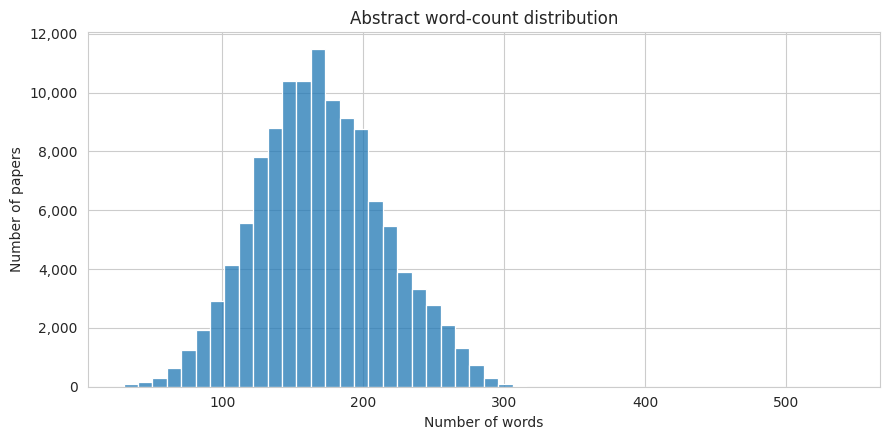

In [6]:
df["abstract_words"] = df["abstract"].fillna("").apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(df["abstract_words"], bins=50, kde=False, ax=ax)
ax.set_title("Abstract word-count distribution")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of papers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig("/kaggle/working/images/abstract_length_histogram.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Abstract length.** Abstract lengths form a roughly bell-shaped curve, slightly skewed to the right, that peaks at about 150–180 words. Most abstracts fall between roughly 100 and 250 words, and very few exceed 300. Extremely short and extremely long abstracts are rare and are kept as legitimate papers (please see the outlier decision in the cleaning notebook for more details).





**5. Title Length Histogram**

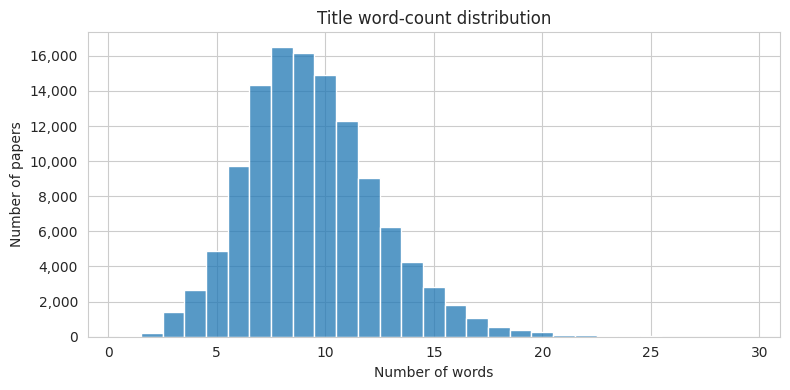

In [7]:
df["title_words"] = df["title"].fillna("").apply(lambda x: len(x.split()))

fig, ax = plt.subplots(figsize=(8, 4))
# discrete=True -> one bar per integer word count (no uneven bins / gaps)
sns.histplot(df["title_words"], discrete=True, kde=False, ax=ax)
ax.set_title("Title word-count distribution")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of papers")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig("/kaggle/working/images/title_length_histogram.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Title length.** Titles are short and fairly symmetric around a median of about 9 words (most fall between 7 and 11), with the most common lengths being 8 and 9 words. A thin right tail runs out to roughly 29 words, and anything above about 17 words is flagged as an outlier by the IQR rule. The year correlation in the heatmap (section 10) is only about 0.11, so titles may be getting slightly longer over 2018–2024, but the effect is very weak.







**6. Boxplot - Abstract vs Title Length**


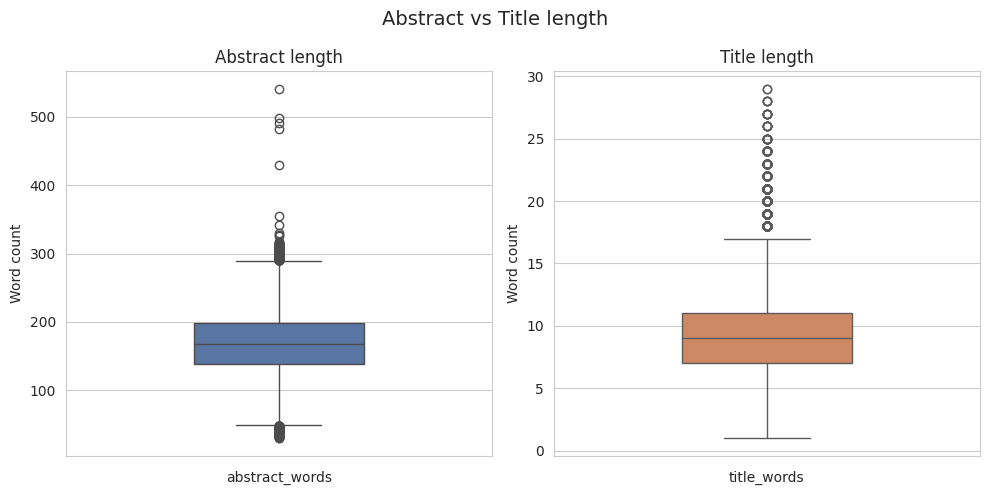

In [8]:
# -------------------------------------------------
# Boxplot: abstract vs title length
# Two panels with independent y-axes, so the title boxplot
# is not squashed by the much larger abstract scale.
# -------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

sns.boxplot(y=df["abstract_words"], ax=axes[0], color="#4C72B0", width=0.4)
axes[0].set_title("Abstract length")
axes[0].set_xlabel("abstract_words")
axes[0].set_ylabel("Word count")

sns.boxplot(y=df["title_words"], ax=axes[1], color="#DD8452", width=0.4)
axes[1].set_title("Title length")
axes[1].set_xlabel("title_words")
axes[1].set_ylabel("Word count")

fig.suptitle("Abstract vs Title length", fontsize=14)
fig.tight_layout()
fig.savefig("/kaggle/working/images/abstract_vs_title_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Abstract vs. title length.** Abstracts are far longer than titles: the median abstract is about 168 words (middle half roughly 140–200) against a median title of about 9 words, roughly 18 times longer. The two are drawn on separate axes because the title scale is tiny next to the abstract scale. Abstracts have outliers on both sides (very short ones below ~50 words and a handful of very long ones, up to about 540 words), while title outliers are only on the long side.






**7. Class Balance after 40k cap**

In [9]:
cat_counts = df["primary_category"].value_counts()
print("Papers per category (capped at 40 k):\n", cat_counts.head(20))
 

Papers per category (capped at 40 k):
 primary_category
cs.CL    39980
cs.CV    39973
cs.LG    39966
Name: count, dtype: int64


**Insight – Class balance.** The three classes are almost perfectly balanced: cs.CL, cs.CV and cs.LG each have roughly 40,000 papers, and the largest and smallest differ by only about 14 papers. This is a result of the 40k-per-category cap applied during data preparation, not of how arXiv actually looks, since the uncapped counts were uneven. So class-imbalance handling is not needed for the classifier, but any category shares computed on this data describe the balanced sample and not all of arXiv.






**8. Category Overlap (Cross listed papers)**

In [10]:
# 'categories' is a space-separated string (e.g. "cs.LG cs.CV"),
# so split on whitespace (commas are also handled, just in case).
cat_lists = df["categories"].str.strip().str.split(r"[,\s]+")
df["n_categories"] = cat_lists.str.len()

overlap = df[df["n_categories"] > 1]
print("Papers cross-listed in >1 category:", len(overlap),
      f"({len(overlap) / len(df):.1%} of all papers)")
print("\nDistribution of number of categories per paper:")
print(df["n_categories"].value_counts().sort_index().to_string())

# Top overlapping pairs
from itertools import combinations
from collections import Counter

pair_counts = Counter()
for cats in cat_lists[df["n_categories"] > 1]:
    cats = sorted({c.strip() for c in cats if c.strip()})
    for pair in combinations(cats, 2):
        pair_counts[pair] += 1
top_pairs = pair_counts.most_common(10)
print("\nTop overlapping category pairs:")
for (a, b), n in top_pairs:
    print(f"  {a} + {b}: {n}")

Papers cross-listed in >1 category: 69412 (57.9% of all papers)

Distribution of number of categories per paper:
n_categories
1    50507
2    40728
3    20673
4     6039
5     1625
6      302
7       42
8        3

Top overlapping category pairs:
  cs.AI + cs.LG: 16797
  cs.LG + stat.ML: 14293
  cs.AI + cs.CL: 13009
  cs.CV + cs.LG: 11829
  cs.CL + cs.LG: 10754
  cs.AI + cs.CV: 7499
  cs.CV + eess.IV: 2813
  cs.AI + stat.ML: 2544
  cs.CR + cs.LG: 2195
  cs.CL + cs.CV: 2183


**Insight – Category overlap.** Cross-listing is common: 69,412 of the 119,919 papers (about 58%) list more than one category, so most papers do not belong to a single field. The most frequent pairs are cs.AI + cs.LG (16,797), cs.LG + stat.ML (14,293), cs.AI + cs.CL (13,009), cs.CV + cs.LG (11,829) and cs.CL + cs.LG (10,754), followed by cs.AI + cs.CV (7,499). The remaining pairs in the top 10 are much smaller, at about 2,200–2,800 papers each. Two things stand out:

- cs.LG is in five of the top ten pairs, so it overlaps with the other two target classes (cs.CV and cs.CL) and with neighbouring categories. Expect it to be the hardest class to separate.
- Many pairs involve categories outside our three targets (cs.AI, stat.ML, eess.IV, cs.CR). These papers were selected by their *primary* category, and the other listed categories are secondary.







**9. Frequent Unigrams and Bigrams**

Top 20 unigrams: [('model', 246615), ('learning', 101279), ('base', 97574), ('datum', 94958), ('dataset', 89693), ('image', 88276), ('language', 82464), ('network', 74732), ('training', 66027), ('learn', 62360), ('feature', 57296), ('neural', 53266), ('large', 52055), ('train', 48617), ('information', 44599), ('text', 43321), ('deep', 43030), ('domain', 42652), ('algorithm', 40268), ('framework', 40224)]
Top 20 bigrams: [('neural network', 30389), ('language model', 27116), ('deep learning', 17364), ('large language', 16704), ('real world', 15990), ('machine learning', 12643), ('natural language', 12428), ('pre train', 11606), ('large scale', 10014), ('reinforcement learning', 9933), ('training datum', 8207), ('fine tuning', 8025), ('learning model', 7560), ('language models', 7442), ('deep neural', 7363), ('end end', 7099), ('high quality', 6721), ('object detection', 6676), ('code available', 6595), ('time series', 6500)]


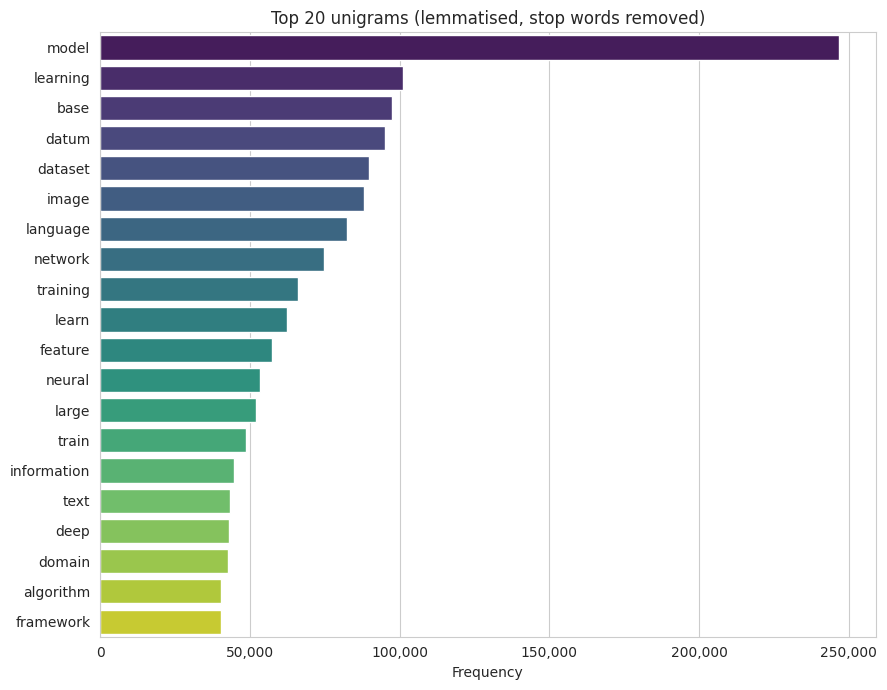

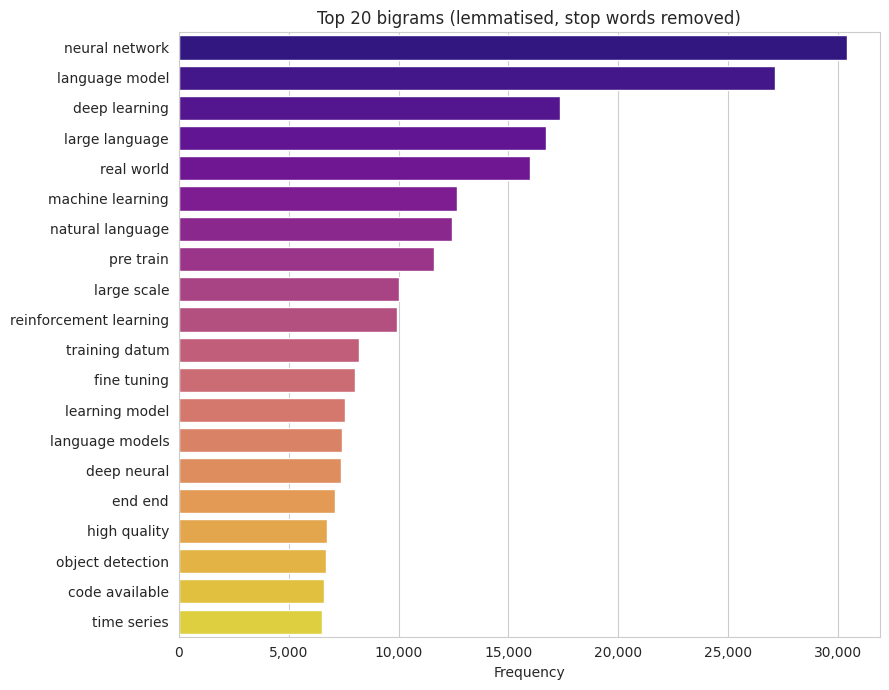

In [11]:
# -------------------------------------------------
# Frequent unigrams & bigrams on the CLEANED text (text_lemma)
# text_lemma is already lower-cased, lemmatised ("model"/"models" -> "model"),
# and has stop words and generic academic words ("paper", "propose", ...) removed,
# so the counts show topical vocabulary rather than words like "the" or "we propose".
# -------------------------------------------------
from collections import Counter

unigram_counter = Counter()
bigram_counter = Counter()

for tokens in df["text_lemma"].fillna("").str.split():
    unigram_counter.update(tokens)
    bigram_counter.update(zip(tokens, tokens[1:]))   # bigrams stay inside one paper

unigrams = unigram_counter.most_common(20)
bigrams = [(f"{a} {b}", n) for (a, b), n in bigram_counter.most_common(20)]

print("Top 20 unigrams:", unigrams)
print("Top 20 bigrams:", bigrams)

# Horizontal bar charts: long labels stay readable and never overlap
# unigram bar chart
uni_labels = [w for w, _ in unigrams]
uni_counts = [c for _, c in unigrams]
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=uni_counts, y=uni_labels, hue=uni_labels, palette="viridis", legend=False, ax=ax)
ax.set_title("Top 20 unigrams (lemmatised, stop words removed)")
ax.set_xlabel("Frequency")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig("/kaggle/working/images/frequent_unigrams.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

# bigram bar chart
bi_labels = [b for b, _ in bigrams]
bi_counts = [c for _, c in bigrams]
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=bi_counts, y=bi_labels, hue=bi_labels, palette="plasma", legend=False, ax=ax)
ax.set_title("Top 20 bigrams (lemmatised, stop words removed)")
ax.set_xlabel("Frequency")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{int(v):,}"))
fig.tight_layout()
fig.savefig("/kaggle/working/images/frequent_bigrams.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Unigrams and bigrams.** These counts use "text_lemma", the same cleaned text that TF-IDF, LDA and the classification baselines will see: lower-cased, lemmatised (so "model" and "models" are one term), with stop words and generic academic words removed. Bigrams are counted within each paper, so no phrase spans two papers. The charts therefore show the topical vocabulary of the corpus instead of function words and abstract boilerplate such as "the", "of" or "we propose".

Read the top terms as the core vocabulary of cs.LG, cs.CL and cs.CV combined. Terms that rank high across the whole corpus are shared by all three fields, so they separate topics poorly on their own. TF-IDF weighting and per-category comparisons are what bring out the discriminative terms.







**10. Correlation Heatmap**

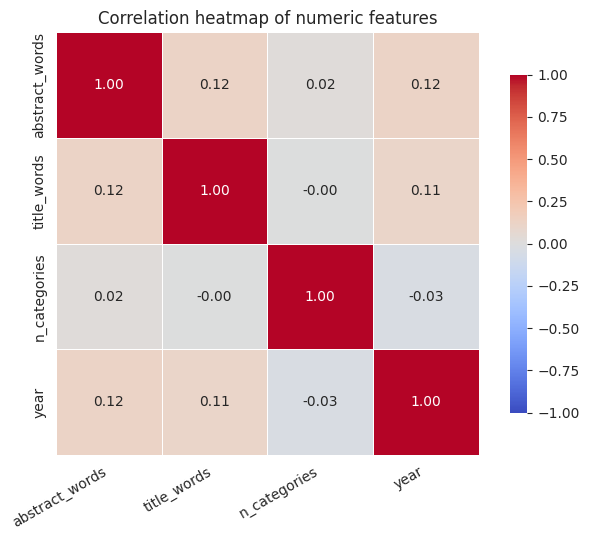

In [12]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")
numeric = df[["abstract_words", "title_words", "n_categories", "year"]].dropna()
corr = numeric.corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)

# A constant column (n_categories is always 1 after cleaning) has no defined
# correlation -> shown as NaN/blank. Label those cells explicitly.
for i, row in enumerate(corr.index):
    for j, col in enumerate(corr.columns):
        if np.isnan(corr.loc[row, col]):
            ax.text(j + 0.5, i + 0.5, "n/a", ha="center", va="center", color="gray")

ax.set_title("Correlation heatmap of numeric features")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig("/kaggle/working/images/corr_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()      # display below the cell
plt.close(fig)

**Insight – Correlations.** Abstract length, title length and year are all weakly and positively correlated (about 0.11–0.12): later papers are slightly longer, and longer titles go with slightly longer abstracts. "n_categories" is essentially uncorrelated with everything else (between -0.03 and 0.02), so cross-listing does not depend on paper length or year. No pair is strong enough to raise multicollinearity concerns.

**Implications for the project:**

- **Class balance:** the classes are balanced by design (about 40k each), so class weights, focal loss or oversampling are not needed. Accuracy is a reasonable metric, but macro-F1 should still be reported, and the report should state that the balance does not reflect real arXiv proportions.
- **Labels and cross-listing:** about 58% of papers list more than one category, so primary_category is a single label for a partly ambiguous problem. Classifier errors should be broken down per class (a confusion matrix), with particular attention to cs.LG against cs.CV and cs.CL, which overlap the most. A multi-label formulation using the full categories field is a possible extension, but would need its own evaluation setup.
- **Vocabulary:** text_lemma gives a clean topical vocabulary for TF-IDF, LDA and other bag-of-words methods (stop words and generic phrases like "we propose" removed, word variants merged). Terms frequent across the whole corpus are shared by all three categories, so use TF-IDF weighting or per-category comparisons to find discriminative terms. Embedding-based methods can keep using text_raw.
- **Text length:** abstracts have a median of about 168 words and a few reach 500 or more. Embedding models that read only about 256 tokens will truncate the longer ones, so fixed-length truncation is a sensible choice, and the few extreme outliers are not a concern.
- **Features:** abstract length, title length, year and number of categories are at most weakly correlated (|r| up to about 0.12), so they can be used together without multicollinearity problems.